## Import Libraries
Import NumPy and pandas for data handling, matplotlib and seaborn for plotting, helper tools (zipfile, glob, tqdm, PIL) for image loading, scikit-learn for splitting and metrics, and TensorFlow for building the CNN. A fixed random seed (42) is set for reproducibility.

In [15]:
import numpy as np
import pandas as pd

import zipfile
from glob import glob
from tqdm import tqdm
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns

tf.keras.utils.set_random_seed(42)

## Download Dataset from Kaggle
Install the Kaggle API and download the MRL eye dataset (`prasadvpatil/mrl-dataset`) with open-eye and closed-eye images.

In [16]:
! pip install -q kaggle
! kaggle datasets download prasadvpatil/mrl-dataset

Dataset URL: https://www.kaggle.com/datasets/prasadvpatil/mrl-dataset
License(s): CC0-1.0
mrl-dataset.zip: Skipping, found more recently modified local copy (use --force to force download)


## Extract Dataset
Unzip `mrl-dataset.zip` into `/content/` to access the `train/Open_Eyes` and `train/Closed_Eyes` folders.

In [17]:
with zipfile.ZipFile('mrl-dataset.zip','r') as zip_ref:
  zip_ref.extractall('/content/')

## Load and Preprocess Images
Load every image from `train/Open_Eyes` (label 1) and `train/Closed_Eyes` (label 0). Each file is converted to grayscale (`convert('L')`) and resized to 64x64 with PIL, then stored as a NumPy array. Corrupt or unreadable files are caught, skipped, and counted for data cleaning.

In [18]:
PATH = '/content/train'

X = []
Y = []
corrupt = []

for i in tqdm(glob(PATH+'/Open_Eyes/*')):
    try:
        temp = np.array(Image.open(i).convert('L').resize((64, 64)))
        X.append(temp)
        Y.append(1)
    except Exception:
        corrupt.append(i)

for i in tqdm(glob(PATH+'/Closed_Eyes/*')):
    try:
        temp = np.array(Image.open(i).convert('L').resize((64, 64)))
        X.append(temp)
        Y.append(0)
    except Exception:
        corrupt.append(i)

print("Successfully loaded :", len(X), "images")
print("Corrupt/skipped     :", len(corrupt), "images")

100%|██████████| 2000/2000 [00:02<00:00, 691.90it/s]

Successfully loaded : 4000 images
Corrupt/skipped     : 0 images


## Exploratory Data Analysis (EDA)
Before training: count each class and compute the balance ratio, print image tensor shape, dtype, pixel value range, and mean intensity, then plot a class-distribution bar chart and one sample image per class.

Class distribution:
  Closed Eye (0): 2000
  Open Eye   (1): 2000
  Balance ratio : 1.0

Image tensor shape : (4000, 64, 64)
Image dtype         : uint8
Pixel value range   : 0 - 255
Mean pixel intensity: 93.06


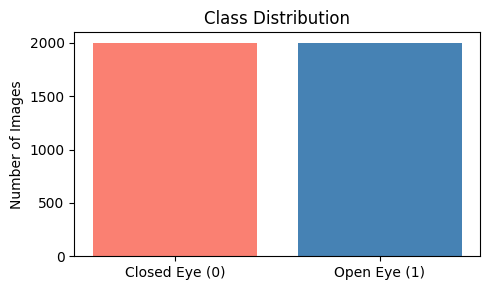

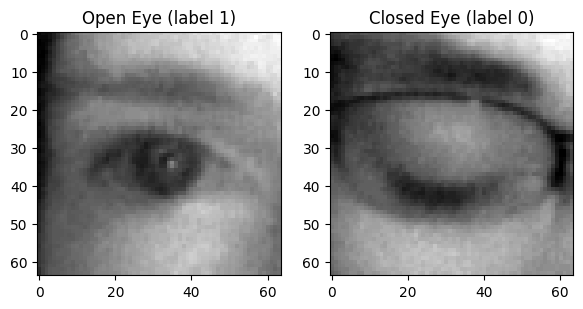

In [19]:
# Class distribution
unique, counts = np.unique(Y, return_counts=True)
class_dist = dict(zip(unique, counts))
n_closed, n_open = class_dist.get(0, 0), class_dist.get(1, 0)

print("Class distribution:")
print("  Closed Eye (0):", n_closed)
print("  Open Eye   (1):", n_open)
print("  Balance ratio :", round(min(n_closed, n_open) / max(n_closed, n_open), 3))

# Basic image statistics
X_arr = np.array(X)
print("\nImage tensor shape :", X_arr.shape)
print("Image dtype         :", X_arr.dtype)
print("Pixel value range   :", X_arr.min(), "-", X_arr.max())
print("Mean pixel intensity:", round(float(X_arr.mean()), 2))

# Bar chart of class distribution
plt.figure(figsize=(5, 3))
plt.bar(['Closed Eye (0)', 'Open Eye (1)'], [n_closed, n_open], color=['salmon', 'steelblue'])
plt.title('Class Distribution')
plt.ylabel('Number of Images')
plt.tight_layout()
plt.show()

# Sample images from each class
plt.figure(figsize=(6, 3))
plt.subplot(1, 2, 1)
plt.imshow(X[0], cmap='gray')
plt.title('Open Eye (label 1)')
plt.subplot(1, 2, 2)
plt.imshow(X[-1], cmap='gray')
plt.title('Closed Eye (label 0)')
plt.tight_layout()
plt.show()

## Split into Train, Validation, and Test Sets
Split the images twice with `train_test_split` (shuffle=True, random_state=42): first hold out 30% as a temporary set, then split that temporary set 50/50 into validation and test. Both calls use `stratify` so the Open/Closed proportion stays balanced in every split. This yields 70% train, 15% validation, and 15% test — the test set is never seen during training.

In [20]:
x_train, x_temp, y_train, y_temp = train_test_split(
    X, Y,
    test_size=0.30,
    random_state=42,
    shuffle=True,
    stratify=Y
)

x_val, x_test, y_val, y_test = train_test_split(
    x_temp, y_temp,
    test_size=0.50,
    random_state=42,
    shuffle=True,
    stratify=y_temp
)

print("Train samples :", len(x_train))
print("Val samples   :", len(x_val))
print("Test samples  :", len(x_test))

Train samples : 2800
Val samples   : 600
Test samples  : 600


## Define Data Augmentation
Build a `Sequential` pipeline of three random layers: horizontal flip, rotation up to 0.1 turns (~36°), and translation up to 20% on both axes (fill with nearest pixel). It is embedded in the model and only applies during training.

In [21]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.1, fill_mode="nearest"),
    tf.keras.layers.RandomTranslation(0.2, 0.2, fill_mode="nearest"),
])

## Build CNN Model
Sequential CNN for (64, 64, 1) input: Rescaling(1/255), the augmentation pipeline, then 4 blocks of Conv2D (32→64→64→128, 3x3, same padding) + BatchNormalization + ReLU + MaxPooling. Head: Flatten → Dense(128, relu) → Dropout(0.5) → Dense(1, sigmoid). Compiled with Adam (lr=0.001), binary_crossentropy, and accuracy.

In [22]:
model = tf.keras.models.Sequential([
    tf.keras.Input(shape=(64, 64, 1)),
    tf.keras.layers.Rescaling(1.0 / 255),

    data_augmentation,

    # Block 1
    tf.keras.layers.Conv2D(32, 3, padding='same'),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Activation('relu'),
    tf.keras.layers.MaxPooling2D(),

    # Block 2
    tf.keras.layers.Conv2D(64, 3, padding='same'),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Activation('relu'),
    tf.keras.layers.MaxPooling2D(),

    # Block 3
    tf.keras.layers.Conv2D(64, 3, padding='same'),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Activation('relu'),
    tf.keras.layers.MaxPooling2D(),

    # Block 4
    tf.keras.layers.Conv2D(128, 3, padding='same'),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Activation('relu'),
    tf.keras.layers.MaxPooling2D(),

    # Classifier head
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dropout(0.5),
    tf.keras.layers.Dense(1, activation='sigmoid'),
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_1 (Rescaling)         │ (None, 64, 64, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential_2 (Sequential)       │ (None, 64, 64, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 64, 64, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_5 (Activation)       │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_6 (Activation)       │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_7 (Activation)       │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 393,153 (1.50 MB)

 Trainable params: 392,577 (1.50 MB)

 Non-trainable params: 576 (2.25 KB)

## Define Callbacks (Early Stopping + Learning Rate Scheduling)
- **EarlyStopping**: monitors `val_loss` and stops training after 10 epochs without improvement, then restores the weights from the epoch with the lowest `val_loss`. Using `val_loss` (not accuracy) avoids stopping prematurely while the loss is still improving.
- **ReduceLROnPlateau**: multiplies the learning rate by 0.5 after 3 epochs without improvement in `val_loss`, down to a floor of 1e-6. Its patience (3) is lower than EarlyStopping's (10), so the LR gets a chance to drop before training stops.

In [23]:
# Stop when val_loss hasn't improved for 10 epochs, keep the best weights
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True,
    verbose=1
)

# Learning rate scheduling: reduce LR when validation loss plateaus
lr_scheduler = tf.keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=3,
    min_lr=1e-6,
    verbose=1
)

## Train the Model
Expand each split to add a channel dimension (64,64) → (64,64,1) and convert labels to NumPy arrays. Build three `tf.data` pipelines with batch size 32: train (shuffle buffer 1000 → batch → prefetch AUTOTUNE), validation and test (batch → prefetch). Fit for up to 30 epochs on `train_ds`, validating on `val_ds`, with `early_stopping` and `lr_scheduler` attached.

In [24]:
# Convert to numpy arrays and add the channel dimension (64, 64) -> (64, 64, 1)
x_train_arr = np.expand_dims(np.array(x_train), axis=-1)
x_val_arr   = np.expand_dims(np.array(x_val), axis=-1)
x_test_arr  = np.expand_dims(np.array(x_test), axis=-1)

y_train_arr = np.array(y_train)
y_val_arr   = np.array(y_val)
y_test_arr  = np.array(y_test)

# Build tf.data input pipelines
BATCH_SIZE = 32

train_ds = (tf.data.Dataset.from_tensor_slices((x_train_arr, y_train_arr))
            .shuffle(1000,
                seed=42,
                reshuffle_each_iteration=True
            )
            .batch(BATCH_SIZE)
            .prefetch(tf.data.AUTOTUNE))

val_ds = (tf.data.Dataset.from_tensor_slices((x_val_arr, y_val_arr))
          .batch(BATCH_SIZE)
          .prefetch(tf.data.AUTOTUNE))

test_ds = (tf.data.Dataset.from_tensor_slices((x_test_arr, y_test_arr))
           .batch(BATCH_SIZE)
           .prefetch(tf.data.AUTOTUNE))

# Train the model
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=30,
    verbose=1,
    callbacks=[early_stopping, lr_scheduler]
)

Epoch 1/30
88/88 ━━━━━━━━━━━━━━━━━━━━ 52s 484ms/step - accuracy: 0.8121 - loss: 0.4637 - val_accuracy: 0.5000 - val_loss: 0.7020 - learning_rate: 0.0010
Epoch 2/30
88/88 ━━━━━━━━━━━━━━━━━━━━ 73s 385ms/step - accuracy: 0.8968 - loss: 0.2514 - val_accuracy: 0.5000 - val_loss: 0.9589 - learning_rate: 0.0010
Epoch 3/30
88/88 ━━━━━━━━━━━━━━━━━━━━ 40s 453ms/step - accuracy: 0.9382 - loss: 0.1647 - val_accuracy: 0.5000 - val_loss: 1.0886 - learning_rate: 0.0010
Epoch 4/30
88/88 ━━━━━━━━━━━━━━━━━━━━ 0s 374ms/step - accuracy: 0.9521 - loss: 0.1296
Epoch 4: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
88/88 ━━━━━━━━━━━━━━━━━━━━ 37s 404ms/step - accuracy: 0.9521 - loss: 0.1230 - val_accuracy: 0.6533 - val_loss: 1.0718 - learning_rate: 0.0010
Epoch 5/30
88/88 ━━━━━━━━━━━━━━━━━━━━ 35s 394ms/step - accuracy: 0.9821 - loss: 0.0544 - val_accuracy: 0.7183 - val_loss: 0.8339 - learning_rate: 5.0000e-04
Epoch 6/30
88/88 ━━━━━━━━━━━━━━━━━━━━ 34s 383ms/step - accuracy: 0.9868 - loss: 

## Training History Visualization
Plot training and validation accuracy and loss across epochs. These learning curves help inspect model convergence and identify possible overfitting, complementing the final test-set evaluation.

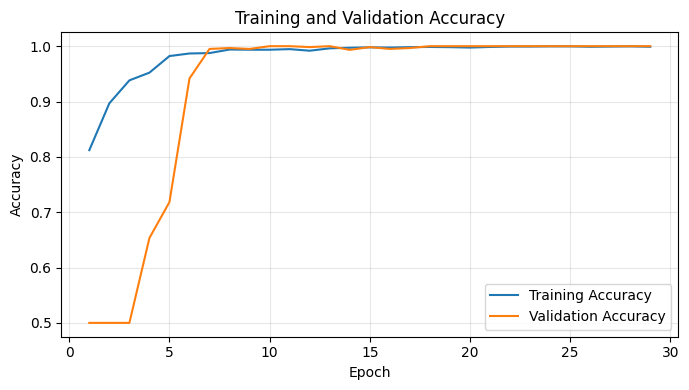

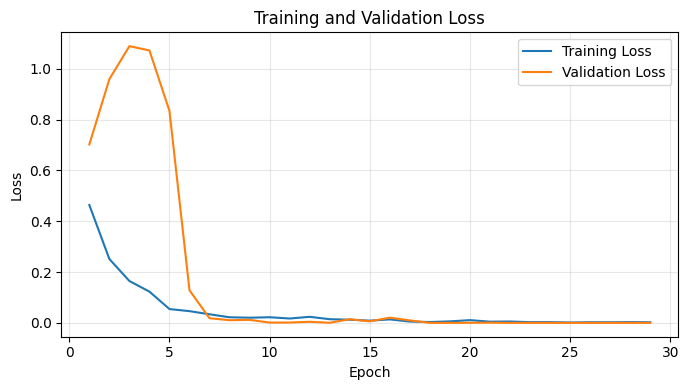

In [25]:
# Plot training and validation accuracy
epochs_range = range(1, len(history.history['accuracy']) + 1)

plt.figure(figsize=(7, 4))
plt.plot(epochs_range, history.history['accuracy'], label='Training Accuracy')
plt.plot(epochs_range, history.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Training and Validation Accuracy')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Plot training and validation loss
plt.figure(figsize=(7, 4))
plt.plot(epochs_range, history.history['loss'], label='Training Loss')
plt.plot(epochs_range, history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training and Validation Loss')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Evaluate the Model
Run `model.evaluate` on the held-out `test_ds` pipeline (600 images, batch 32) to report the final binary cross-entropy loss and accuracy on data never used for training or validation.

In [26]:
# Evaluate on the held-out test tf.data pipeline
test_loss, test_accuracy = model.evaluate(test_ds, verbose=1)
print(f"Test loss: {test_loss:.6f}")
print(f"Test accuracy: {test_accuracy:.4%}")

19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 70ms/step - accuracy: 1.0000 - loss: 1.4457e-05
Test loss: 0.000014
Test accuracy: 100.0000%


## Evaluation Metrics & Visualization
Predict probabilities on `test_ds`, threshold at 0.5, and use `ravel()` to convert predictions to a 1-D array matching `y_test_arr`. Print a `classification_report` with precision, recall, and F1-score for each class (4 decimal places), then plot a confusion-matrix heatmap with Actual on the y-axis and Predicted on the x-axis.

19/19 ━━━━━━━━━━━━━━━━━━━━ 2s 80ms/step
--- Classification Report (Precision & Recall) ---
              precision    recall  f1-score   support

      Closed     1.0000    1.0000    1.0000       300
        Open     1.0000    1.0000    1.0000       300

    accuracy                         1.0000       600
   macro avg     1.0000    1.0000    1.0000       600
weighted avg     1.0000    1.0000    1.0000       600



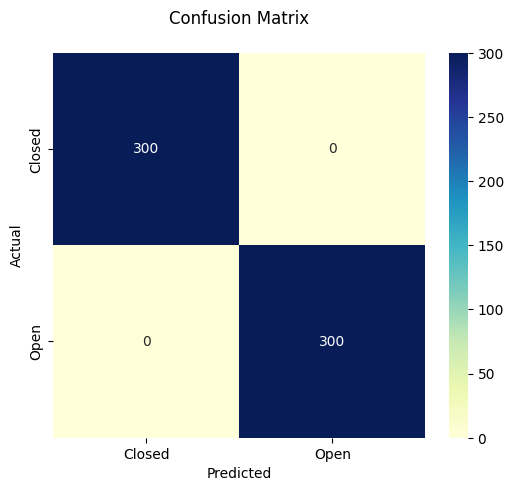

In [27]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

# Predict on the test set
preds = model.predict(test_ds)
# Flatten predictions to 1-D so their shape matches y_test_arr
preds_binary = (preds >= 0.5).astype(np.int32).ravel()

# Precision, Recall, F1-score
print("--- Classification Report (Precision & Recall) ---")
print(classification_report(
    y_test_arr,
    preds_binary,
    target_names=['Closed', 'Open'],
    digits=4
))

# Confusion matrix
cm = confusion_matrix(y_test_arr, preds_binary)
df_cm = pd.DataFrame(cm, index=['Closed', 'Open'], columns=['Closed', 'Open'])

plt.figure(figsize=(6, 5))
plt.title("Confusion Matrix\n")
sns.heatmap(df_cm, annot=True, fmt="d", cmap="YlGnBu")
plt.ylabel("Actual")
plt.xlabel("Predicted")
plt.show()

## Save Model
Export the trained model (architecture + weights + optimizer state) to `/content/StayAwake.keras` in Keras format for later inference or resuming training.

In [28]:
model.save('/content/StayAwake.keras')